# 03 - Prévision de la demande hebdomadaire

**Question métier** : combien d'unités seront vendues par groupe de catégories dans les **12 prochaines semaines** ?

**Ce que l'EDA (01) impose**
- Une **rupture en octobre 2017** (nouveau catalogue, volumes erratiques) : on ne modélise que la **période stable**,
  du 05/01/2015 au 18/09/2017 (142 semaines complètes). Forcer un modèle sur la période d'après rupture n'aurait pas de sens.
- Les **marchés changent d'un trimestre à l'autre** : pas de prévision par région, mais **par catégorie**.
- 9 catégories font ~95 % du CA : 9 séries + 1 série « Autres » = **10 séries**.
- **Pas de saisonnalité annuelle** détectée : la naïve saisonnière risque d'être une baseline faible ; on ajoute une moyenne mobile.

**Protocole** : backtest à origine glissante, 4 plis de 12 semaines sans chevauchement (les 48 dernières semaines stables).
Chaque prévision n'utilise que l'historique antérieur à son origine. Métriques : MAPE, RMSE (+ WAPE et biais).

In [1]:
import sys, warnings, json, logging
from pathlib import Path

RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RACINE))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, wilcoxon

from src.config import MODELS_DIR, SQL_DIR, set_seed
from src.etl.load import copier_dataframe, creer_moteur, executer_script_sql
from src.models import prevision as P

set_seed()
pd.set_option("display.width", 160)
BLEU, ORANGE, AQUA, JAUNE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
COULEURS = {"naive_saisonniere": GRIS, "moyenne_mobile_12": AQUA, "prophet": JAUNE, "xgboost": ORANGE}
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c8c7c2", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
})
engine = creer_moteur()

## 1. Les séries

Semaines disponibles : 162 (2014-12-29 -> 2018-01-29)
Période stable       : 142 (2015-01-05 -> 2017-09-18)


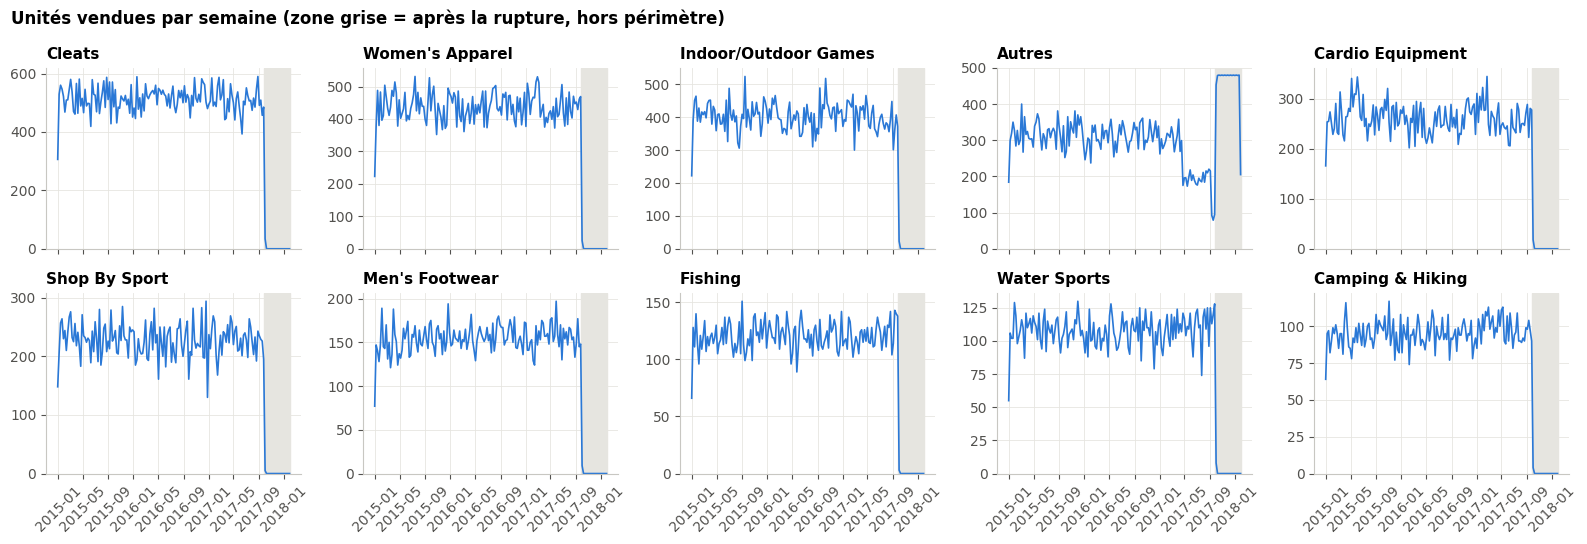

,unités/semaine (moy.),coef. de variation,évolution 2017 vs 2015
groupe_prevision,,,
Cleats,513.444,0.079,-0.010
Women's Apparel,438.303,0.095,0.000
Indoor/Outdoor Games,402.718,0.102,-0.025
Autres,294.535,0.193,-0.269
Cardio Equipment,261.444,0.115,-0.027
Shop By Sport,228.014,0.123,-0.015
Men's Footwear,155.014,0.095,0.027
Fishing,120.549,0.098,0.011
Water Sports,108.092,0.100,0.011


In [2]:
series = P.charger_series(engine)          # toutes les semaines disponibles
stable = P.periode_stable(series)          # période modélisée
print(f"Semaines disponibles : {len(series)} ({series.index[0].date()} -> {series.index[-1].date()})")
print(f"Période stable       : {len(stable)} ({stable.index[0].date()} -> {stable.index[-1].date()})")

ordre = stable.mean().sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5), sharex=True)
for ax, g in zip(axes.flat, ordre):
    ax.plot(series.index, series[g], color=BLEU, lw=1.2)
    ax.axvspan(P.FIN_STABLE + pd.Timedelta(weeks=1), series.index[-1], color="#e6e5e0", zorder=0)
    ax.set_title(g, loc="left")
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Unités vendues par semaine (zone grise = après la rupture, hors périmètre)", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

pd.DataFrame({"unités/semaine (moy.)": stable.mean(), "coef. de variation": stable.std() / stable.mean(),
              "évolution 2017 vs 2015": stable.loc["2017"].mean() / stable.loc["2015"].mean() - 1}).loc[ordre].round(3)

> Les 9 catégories principales sont **stationnaires** (variation de 8 à 12 % autour d'un niveau stable, pas de tendance nette).
> « Autres » est plus bruitée (~19 %) et **décroît** (-27 % entre 2015 et 2017) : c'est la série la plus difficile.

## 2. Backtest des 4 modèles

In [3]:
print("Origines des plis :", [stable.index[o].date() for o in P.origines_backtest(len(stable))])
bt = P.backtest(stable)
print(f"{len(bt)} prévisions ({bt['modele'].nunique()} modèles x {P.N_PLIS} plis x {P.HORIZON} semaines x {stable.shape[1]} séries)")

global_ = P.metriques(bt, ["modele"]).sort_values("MAPE")
global_.style.format({"MAPE": "{:.2%}", "RMSE": "{:.1f}", "WAPE": "{:.2%}", "biais": "{:+.2%}"})

Importing plotly failed. Interactive plots will not work.


Origines des plis : [datetime.date(2016, 10, 24), datetime.date(2017, 1, 16), datetime.date(2017, 4, 10), datetime.date(2017, 7, 3)]


22:18:47 - cmdstanpy - INFO - Chain [1] start processing


22:18:48 - cmdstanpy - INFO - Chain [1] done processing


22:18:48 - cmdstanpy - INFO - Chain [1] start processing


22:18:49 - cmdstanpy - INFO - Chain [1] done processing


... (14 outputs left out)

22:18:54 - cmdstanpy - INFO - Chain [1] start processing


22:18:54 - cmdstanpy - INFO - Chain [1] done processing


1920 prévisions (4 modèles x 4 plis x 12 semaines x 10 séries)


,MAPE,RMSE,WAPE,biais
modele,,,,
xgboost,10.11%,34.8,9.17%,+0.75%
moyenne_mobile_12,10.23%,34.9,9.25%,+1.64%
prophet,11.22%,37.4,9.94%,+1.00%
naive_saisonniere,14.22%,46.6,12.42%,+1.74%


In [4]:
par_groupe = P.metriques(bt, ["groupe_prevision", "modele"])["MAPE"].unstack().loc[ordre]
par_pli = P.metriques(bt, ["modele", "pli"])["MAPE"].unstack()
display((par_groupe * 100).round(1).rename_axis("MAPE % par série"))
display((par_pli * 100).round(1).rename_axis("MAPE % par pli"))

modele,moyenne_mobile_12,naive_saisonniere,prophet,xgboost
MAPE % par série,,,,
Cleats,7.2,8.5,6.8,7.0
Women's Apparel,9.2,10.0,8.8,8.5
Indoor/Outdoor Games,8.1,9.6,7.9,8.7
Autres,24.0,41.4,29.1,24.0
Cardio Equipment,10.4,13.0,12.2,9.0
Shop By Sport,10.3,15.0,11.2,10.4
Men's Footwear,8.3,11.7,9.7,8.3
Fishing,8.0,12.0,8.9,7.9
Water Sports,8.7,12.0,9.7,8.9


pli,1,2,3,4
MAPE % par pli,,,,
moyenne_mobile_12,8.9,8.7,13.4,9.9
naive_saisonniere,11.6,11.0,15.3,19.0
prophet,9.5,9.3,13.1,13.0
xgboost,8.9,9.1,12.7,9.8


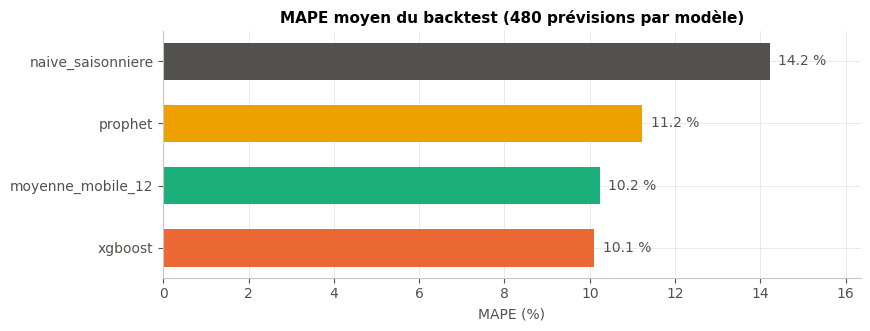

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
g = global_["MAPE"].sort_values()
ax.barh(g.index, g.values * 100, color=[COULEURS[m] for m in g.index], height=0.6)
for y, v in enumerate(g.values * 100):
    ax.text(v + 0.2, y, f"{v:.1f} %", va="center", color=GRIS)
ax.set(title="MAPE moyen du backtest (480 prévisions par modèle)", xlabel="MAPE (%)", xlim=(0, g.max() * 115))
plt.show()

## 3. Choix du modèle : la différence est-elle réelle ?

**Règle fixée** : on retient le modèle au MAPE le plus bas, **sauf** si sa différence avec un modèle plus simple
n'est pas statistiquement significative (test apparié sur les mêmes 480 semaines x séries, seuil 5 %).
Dans ce cas, on garde le plus simple (plus facile à expliquer, à maintenir, et moins risqué).
Ordre de simplicité : naïve saisonnière < moyenne mobile < Prophet < XGBoost.

In [6]:
SIMPLICITE = ["naive_saisonniere", "moyenne_mobile_12", "prophet", "xgboost"]
bt["erreur_abs_pct"] = (bt["quantite_prevue"] - bt["quantite_reelle"]).abs() / bt["quantite_reelle"]
erreurs = bt.pivot_table(index=["debut_semaine", "groupe_prevision"], columns="modele", values="erreur_abs_pct")

meilleur = global_.index[0]
MODELE_RETENU = meilleur
tests = []
for plus_simple in SIMPLICITE[: SIMPLICITE.index(meilleur)]:
    diff = erreurs[plus_simple] - erreurs[meilleur]
    p_t, p_w = ttest_rel(erreurs[plus_simple], erreurs[meilleur]).pvalue, wilcoxon(diff).pvalue
    tests.append({"comparaison": f"{plus_simple} vs {meilleur}", "écart MAPE (pts)": diff.mean() * 100,
                  "p (t apparié)": p_t, "p (Wilcoxon)": p_w})
    if max(p_t, p_w) > 0.05 and MODELE_RETENU == meilleur:
        MODELE_RETENU = plus_simple   # premier modèle plus simple statistiquement équivalent
display(pd.DataFrame(tests).round(4))
print("Meilleur MAPE :", meilleur, "| Modèle retenu :", MODELE_RETENU)

,comparaison,écart MAPE (pts),p (t apparié),p (Wilcoxon)
0,naive_saisonniere vs xgboost,4.1104,0.0000,0.0000
1,moyenne_mobile_12 vs xgboost,0.1206,0.4998,0.6875
2,prophet vs xgboost,1.1154,0.0003,0.0024


Meilleur MAPE : xgboost | Modèle retenu : moyenne_mobile_12


## 4. Visualiser le backtest

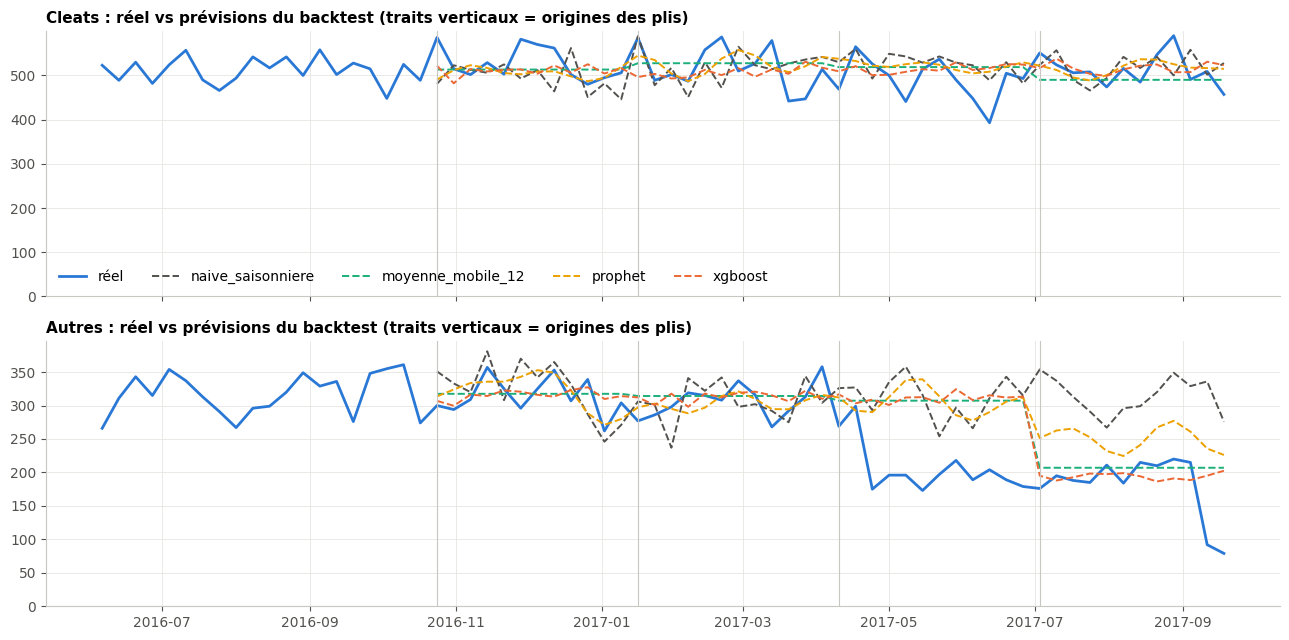

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
debut = stable.index[P.origines_backtest(len(stable))[0]] - pd.Timedelta(weeks=20)
for ax, g in zip(axes, ["Cleats", "Autres"]):
    ax.plot(stable.loc[debut:].index, stable.loc[debut:, g], color=BLEU, lw=2, label="réel")
    for m in ["naive_saisonniere", "moyenne_mobile_12", "prophet", "xgboost"]:
        s = bt[(bt["modele"] == m) & (bt["groupe_prevision"] == g)].sort_values("debut_semaine")
        ax.plot(s["debut_semaine"], s["quantite_prevue"], color=COULEURS[m], lw=1.4, ls="--", label=m)
    for o in P.origines_backtest(len(stable)):
        ax.axvline(stable.index[o], color="#c8c7c2", lw=0.8)
    ax.set_title(f"{g} : réel vs prévisions du backtest (traits verticaux = origines des plis)", loc="left")
    ax.set_ylim(bottom=0)
axes[0].legend(ncol=5, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

## 5. Prévisions des 12 semaines suivantes

Chaque modèle est ré-entraîné sur les 142 semaines stables, puis prévoit du 25/09/2017 au 11/12/2017.
Intervalles à 80 % : natifs pour Prophet ; pour les autres modèles, quantiles des erreurs relatives observées en backtest.

In [8]:
futur = {}
for m in P.MODELES:
    prev, bas, haut = P.FONCTIONS[m](stable)
    if bas is None:
        bas, haut = P.intervalles_empiriques(bt, m, prev)
    futur[m] = (prev, bas, haut)

prev, bas, haut = futur[MODELE_RETENU]
tableau = pd.DataFrame({"prévision 12 sem. (unités)": prev.sum(), "borne basse": bas.sum(), "borne haute": haut.sum(),
                        "moyenne hebdo des 12 dernières sem.": stable.iloc[-12:].mean() * 12}).loc[ordre].round(0)
tableau.loc["TOTAL"] = tableau.sum()
print("Modèle retenu :", MODELE_RETENU)
tableau

Modèle retenu : moyenne_mobile_12


,prévision 12 sem. (unités),borne basse,borne haute,moyenne hebdo des 12 dernières sem.
groupe_prevision,,,,
Cleats,6158.0,5491.0,6857.0,6158.0
Women's Apparel,5213.0,4482.0,5818.0,5213.0
Indoor/Outdoor Games,4582.0,4019.0,5018.0,4582.0
Autres,2170.0,1314.0,2309.0,2170.0
Cardio Equipment,3086.0,2648.0,3633.0,3086.0
Shop By Sport,2726.0,2345.0,3154.0,2726.0
Men's Footwear,1874.0,1618.0,2079.0,1874.0
Fishing,1492.0,1335.0,1722.0,1492.0
Water Sports,1350.0,1194.0,1521.0,1350.0


> Les bornes de chaque série sont additionnées pour la ligne TOTAL : c'est une approximation prudente (elle suppose
> que toutes les séries se trompent dans le même sens), l'intervalle réel du total est plus étroit.

## 6. Confrontation avec ce qui s'est réellement passé (hors évaluation)

Les données couvrent aussi les 12 semaines prévues, mais elles tombent **après la rupture** de catalogue.
On les montre pour illustrer la limite de toute prévision fondée sur l'historique ; elles ne servent **pas** à choisir le modèle.

,prévu (modèle retenu),réel,écart %
groupe_prevision,,,
Cleats,6158.0,519.0,-91.6
Women's Apparel,5213.0,494.0,-90.5
Indoor/Outdoor Games,4582.0,395.0,-91.4
Autres,2170.0,5343.0,146.2
Cardio Equipment,3086.0,296.0,-90.4
Shop By Sport,2726.0,200.0,-92.7
Men's Footwear,1874.0,157.0,-91.6
Fishing,1492.0,141.0,-90.5
Water Sports,1350.0,136.0,-89.9


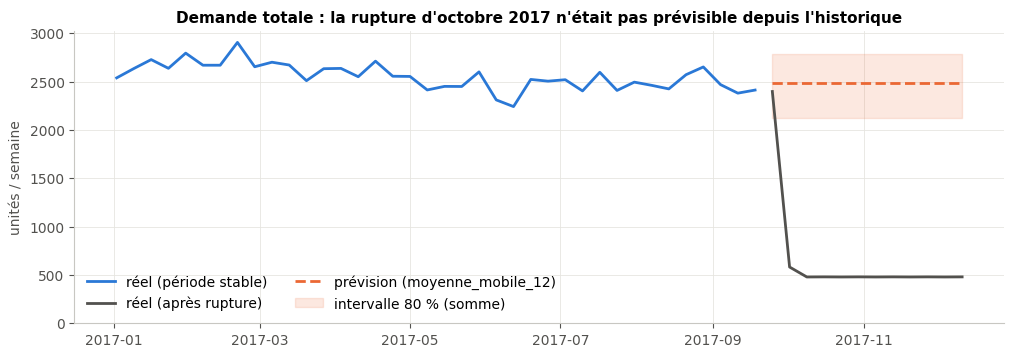

In [9]:
reel_futur = series.loc[prev.index]
comparaison = pd.DataFrame({"prévu (modèle retenu)": prev.sum(), "réel": reel_futur.sum()}).loc[ordre]
comparaison["écart %"] = (comparaison["réel"] / comparaison["prévu (modèle retenu)"] - 1) * 100
comparaison.loc["TOTAL"] = [comparaison.iloc[:, 0].sum(), comparaison.iloc[:, 1].sum(),
                            (comparaison.iloc[:, 1].sum() / comparaison.iloc[:, 0].sum() - 1) * 100]
display(comparaison.round(1))

total_hist = stable.sum(axis=1)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(total_hist.loc["2017"].index, total_hist.loc["2017"], color=BLEU, lw=2, label="réel (période stable)")
ax.plot(series.loc[prev.index].index, series.loc[prev.index].sum(axis=1), color=GRIS, lw=2, label="réel (après rupture)")
ax.plot(prev.index, prev.sum(axis=1), color=ORANGE, lw=2, ls="--", label=f"prévision ({MODELE_RETENU})")
ax.fill_between(prev.index, bas.sum(axis=1), haut.sum(axis=1), color=ORANGE, alpha=0.15, label="intervalle 80 % (somme)")
ax.set(title="Demande totale : la rupture d'octobre 2017 n'était pas prévisible depuis l'historique", ylabel="unités / semaine")
ax.set_ylim(bottom=0); ax.legend(frameon=False, ncol=2); plt.show()

## 7. Écriture des prévisions dans PostgreSQL

In [10]:
lignes = []
b = bt.drop(columns="erreur_abs_pct").assign(type_prevision="backtest")
lignes.append(b)
for m, (prev_m, bas_m, haut_m) in futur.items():
    f = P._en_long(prev_m, bas_m, haut_m, m)
    f["type_prevision"], f["pli"], f["quantite_reelle"] = "futur", pd.NA, np.nan
    f["horizon"] = f.groupby("groupe_prevision").cumcount() + 1
    lignes.append(f)
pred = pd.concat(lignes, ignore_index=True)
pred["est_modele_retenu"] = pred["modele"] == MODELE_RETENU
pred["pli"] = pred["pli"].astype("Int64")
for c in ["quantite_prevue", "borne_basse", "borne_haute", "quantite_reelle"]:
    pred[c] = pred[c].astype(float).round(2)
colonnes = ["debut_semaine", "groupe_prevision", "modele", "type_prevision", "pli", "horizon",
            "quantite_prevue", "borne_basse", "borne_haute", "quantite_reelle", "est_modele_retenu"]
pred["debut_semaine"] = pd.to_datetime(pred["debut_semaine"]).dt.date

executer_script_sql(engine, SQL_DIR / "07_pred_demande.sql")
with engine.begin() as conn:
    conn.exec_driver_sql("TRUNCATE ml.pred_demande")
copier_dataframe(engine, pred[colonnes], "pred_demande", schema="ml")
executer_script_sql(engine, SQL_DIR / "05_vues_powerbi.sql")   # (re)crée bi.fait_prevision

# Métadonnées utilisées par l'API (/forecast)
meta = {"modele_retenu": MODELE_RETENU, "meilleur_mape": meilleur,
        "periode_stable": [str(stable.index[0].date()), str(stable.index[-1].date())],
        "horizon_semaines": P.HORIZON,
        "metriques_backtest": {m: {k: float(v) for k, v in r.items()} for m, r in global_.iterrows()}}
(MODELS_DIR / "prevision.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

pd.read_sql("SELECT type_prevision, modele, COUNT(*) AS lignes, MIN(debut_semaine) AS debut, MAX(debut_semaine) AS fin, "
            "BOOL_OR(est_modele_retenu) AS retenu FROM ml.pred_demande GROUP BY 1, 2 ORDER BY 1, 2", engine)

,type_prevision,modele,lignes,debut,fin,retenu
0,backtest,moyenne_mobile_12,480,2016-10-24,2017-09-18,True
1,backtest,naive_saisonniere,480,2016-10-24,2017-09-18,False
2,backtest,prophet,480,2016-10-24,2017-09-18,False
3,backtest,xgboost,480,2016-10-24,2017-09-18,False
4,futur,moyenne_mobile_12,120,2017-09-25,2017-12-11,True
5,futur,naive_saisonniere,120,2017-09-25,2017-12-11,False
6,futur,prophet,120,2017-09-25,2017-12-11,False
7,futur,xgboost,120,2017-09-25,2017-12-11,False


## 8. Conclusions

- Sur la période stable, la demande hebdomadaire par catégorie se prévoit avec un **MAPE d'environ 10 %** :
  c'est essentiellement le bruit semaine à semaine autour d'un niveau stable.
- La **naïve saisonnière** est la moins bonne : il n'y a pas de saisonnalité annuelle à exploiter (01_eda).
- **XGBoost et la moyenne mobile 12 semaines sont statistiquement à égalité** : on retient le plus simple quand le test ne
  distingue pas les deux (règle de la section 3). Prophet se situe entre les deux.
- « Autres » concentre l'erreur (MAPE ~24 % contre 7-10 % pour les autres) : série hétérogène et en déclin.
- **Limite majeure** : la rupture d'octobre 2017 rend l'historique caduc. Aucun modèle statistique ne pouvait l'anticiper.
- **Alternatives proposées** pour la période après rupture : (1) prévoir au niveau **total** ou **département** le temps
  d'accumuler 6 à 12 mois d'historique sur le nouveau catalogue ; (2) prévision par **analogie** (nouveaux produits
  rattachés à des produits existants comparables) ; (3) intégrer l'information **planifiée** (lancements, promotions)
  plutôt que de l'apprendre a posteriori.